<center style="padding: 1em 2em; margin: 1em 0;">
    <h1 style="font-size: 2.2em; margin: 0; color: rgb(52, 72, 92);">«Numerical Python»</h1>
</center>


Сегодня познакомимся с NumPy: библиотекой для работы с числовыми массивами. Она полезна, когда нужно обработать сразу много измерений, выполнить вычисление над таблицей чисел или представить изображение как данные.

Начнём с одного ряда, затем разберём форму и устройство массива, а в конце поработаем с фотографией. Ещё заглянем в подмодуль `numpy.random`, который создаёт случайные данные для опытов и моделирования.

У NumPy есть и другие подмодули: например, `numpy.linalg` для линейной алгебры и `numpy.fft` для преобразования Фурье. Первого коснёмся коротко; подробности этих инструментов лучше изучать на соответствующих математических дисциплинах.

---

## **План урока**

1. **Массив и скорость**: первое вычисление и сравнение со списком.
2. **Устройство массива**: оси, форма, тип, буфер, срезы и копии.
3. **Операции**: знаки Python, `ufunc` и `np.vectorize`.
4. **Несколько осей**: `axis`, broadcasting и маски.
5. **`random`**: прямые функции, зерно и отдельный генератор.
6. **Изображение**: пиксели, яркость, уменьшение данных и размытие.

---

## **Зачем нужен массив**

Датчик записал четыре длительности в секундах. Переведём каждую в минуты. Со списком мы умеем это делать: берём одно значение, делим на 60, повторяем для следующего.


In [1]:
seconds_list = [30, 60, 90, 120]
[value / 60 for value in seconds_list]


[0.5, 1.0, 1.5, 2.0]

Результат верен. Но задача звучит как «разделить весь ряд», а код описывает обход отдельных объектов. NumPy позволяет написать действие над рядом прямо.


In [2]:
import numpy as np

seconds = np.array(seconds_list)
seconds


array([ 30,  60,  90, 120])

`np` – принятое короткое имя библиотеки *Numerical Python*. `np.array` взял значения списка и создал `ndarray`. Пока это один ряд, то есть массив с одной осью.


In [3]:
seconds / 60


array([0.5, 1. , 1.5, 2. ])

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #64748b; background-color: #f8fafc; color: #475569;">
<strong><code>ndarray</code>:</strong><br>Массив NumPy: значения одного типа и описание того, как читать их по осям. Операция над всем массивом применяется к его элементам.
</div>


### **Почему NumPy быстрее?**

Массив напечатался без запятых: это уже не список. У числового массива значения одного типа лежат рядом в памяти. Списку же нужны ссылки на отдельные объекты Python.

Когда мы пишем `seconds / 60`, Python передаёт NumPy весь массив. Внутренний цикл выполняет деление над числами, не вызывая отдельную Python-операцию для каждого элемента.

Срез массива часто читает прежние данные без новой копии. Позже увидим, как это устроено. На маленьких данных вызов NumPy тоже стоит времени, поэтому преимущество лучше проверить измерением.

### **Сравнение скорости**

Возьмём одну задачу: удвоить 200 000 чисел. Подготовку данных не включаем в замер. `np.array_equal` сначала проверит, что список и массив дают одинаковый ответ. Для времени используем `timeit.repeat`: он повторит вычисление несколько раз.

In [4]:
from timeit import repeat

python_data = list(range(200_000))
numpy_data = np.array(python_data)
np.array_equal([value * 2 for value in python_data], numpy_data * 2)


True

Сначала измерим обход списка на Python. Повторяем опыт несколько раз и делим время серии на число запусков.


In [5]:
python_ms = min(repeat(lambda: [value * 2 for value in python_data], number=3, repeat=5)) / 3 * 1000
round(python_ms, 2)  # миллисекунды


3.84

Теперь та же арифметика над числовым массивом.


In [6]:
numpy_ms = min(repeat(lambda: numpy_data * 2, number=3, repeat=5)) / 3 * 1000
round(numpy_ms, 2)  # миллисекунды


0.07

Отношение времён помогает оценить разницу именно в этом опыте. На маленьких массивах вызов NumPy тоже стоит времени; на больших может мешать создание промежуточных массивов.


In [7]:
round(python_ms / numpy_ms, 1)  # во сколько раз быстрее в этом запуске


53.5

На этой машине получился один конкретный результат, а не постоянный коэффициент ускорения. Теперь разберём, как NumPy описывает значения и оси массива.

---

### **Оси и форма**

У ряда длительностей одна ось: номер измерения. Если датчик записывает три величины в каждый момент, понадобится вторая ось. Строка будет моментом времени, столбец будет величиной. В цветной фотографии появится третья ось, канал цвета.

`shape` хранит длину каждой оси, `ndim` показывает число осей, `size` считает все элементы. `len` смотрит только на первую ось.

![Размерности массивов](../../Other/images/01_dims.png)


In [8]:
measurements = np.array([
    [10, 20, 30],
    [12, 19, 31],
    [11, 21, 29],
])
measurements


array([[10, 20, 30],
       [12, 19, 31],
       [11, 21, 29]])

В первой оси идут три момента, во второй – три показателя. Длину каждой оси хранит `shape`. Число осей – `ndim`.


In [9]:
measurements.shape, measurements.ndim


((3, 3), 2)

`size` считает все девять значений, а `len` только первую ось, три строки. Для таблицы это разные вопросы.


In [10]:
measurements.size, len(measurements)


(9, 3)

## **Тип и буфер**

Форма говорит, где находятся элементы, а `dtype` – как их понимать. Для обычного числового массива все значения имеют один тип. Укажем `int32` явно: тогда на одно число приходится четыре байта независимо от платформы.


In [11]:
small = np.array([1, 2, 3, 4], dtype=np.int32)
small.dtype, small.itemsize, small.nbytes


(dtype('int32'), 4, 16)

`itemsize` относится к одному элементу, `nbytes` – к данным всех элементов. Здесь четыре числа занимают 16 байт; служебные данные самого объекта массива в `nbytes` не входят.

Что будет, если рядом с целыми появится дробь? NumPy подберёт один общий тип.


In [12]:
np.array([1, 2.5, 3])


array([1. , 2.5, 3. ])

Все три значения стали вещественными: массив выбрал общий числовой тип. Список может хранить объекты разных типов, а числовой `ndarray` обычно хранит значения одинакового размера в одном буфере. Сам объект массива хранит также тип, форму и шаги чтения.

### **Какие бывают типы?**

В названии числового типа число обычно показывает, сколько **бит** занимает один элемент. Восемь бит – один байт. Тип выбирают с учётом того, какие значения нужны и сколько памяти можно потратить.

- `int8`, `int16`, `int32`, `int64` – целые числа со знаком. Например, `int8` хранит числа от −128 до 127.
- `uint8`, `uint16`, `uint32`, `uint64` – целые без знака. У `uint8` диапазон от 0 до 255, поэтому он удобен для цветовых каналов изображения.
- `float32`, `float64` – числа с дробной частью. `float32` занимает 4 байта и хранит меньше точных цифр, чем восьмибайтовый `float64`.

Есть также `bool` для `True` и `False`, `complex64` и `complex128` для комплексных чисел, типы дат и времени `datetime64` и `timedelta64`. Ниже встретятся и строки.

Возьмём три маленьких целых числа. Проверим, сколько места они занимают в `int8`.

In [13]:
tiny = np.array([1, 2, 3], dtype=np.int8)
tiny.dtype, tiny.nbytes

(dtype('int8'), 3)

`astype` создаёт массив другого типа. Те же три числа в `int64` займут больше места; зато этот тип вмещает гораздо большие целые числа.

In [14]:
wide = tiny.astype(np.int64)
wide.dtype, wide.nbytes

(dtype('int64'), 24)

Преобразование меняет и значения, если новый тип не может сохранить их точно. При переводе дробных чисел в целые дробная часть отбрасывается, а не округляется.

In [15]:
np.array([1.9, -1.9]).astype(np.int32)

array([ 1, -1], dtype=int32)

Со строками тоже есть тонкость. Тип `<U3` оставляет место для **трёх символов** в каждом элементе. Если записать более длинное слово в готовый массив, оно обрежется.

In [16]:
words = np.array(["кот", "лес"], dtype="<U3")
words[0] = "собака"
words

array(['соб', 'лес'], dtype='<U3')

У NumPy есть и `object`: такой массив может хранить обычные объекты Python разных типов. В его буфере лежат ссылки на объекты, а сами значения могут находиться в разных местах памяти. Поэтому преимущества компактного числового хранения обычно теряются. Для таблицы с именем, возрастом и городом скоро возьмём pandas: там разные типы могут жить в разных столбцах.

Для знакомства с шагами памяти выпишем таблицу вручную. Позже научимся строить её из ряда с помощью `reshape`.

In [17]:
grid = np.array([
    [0, 1, 2, 3],
    [4, 5, 6, 7],
    [8, 9, 10, 11],
], dtype=np.int32)
grid

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]], dtype=int32)

### **Шаги в памяти**

На экране `grid` выглядит как таблица, но его числа лежат в памяти подряд: сначала первая строка, затем вторая и третья. Как NumPy находит число по двум индексам? Он начинает с первого элемента и считает, на сколько **байт** сдвинуться по каждой оси.

У нас `int32`: одно число занимает 4 байта. Посмотрим на шаги массива.

In [18]:
grid.strides

(16, 4)

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #64748b; background-color: #f8fafc; color: #475569;">
<strong><code>strides</code>:</strong><br>На сколько байт сдвинуться, чтобы перейти к следующему элементу вдоль каждой оси. У каждой оси свой шаг.
</div>

Получилось `(16, 4)`. Чтобы перейти **к той же позиции в следующей строке**, нужно пройти 16 байт: четыре числа по 4 байта. Для соседнего столбца достаточно 4 байт.

Например, от `grid[0, 0]` до `grid[1, 2]` нужно пройти одну строку и два столбца: `1 × 16 + 2 × 4 = 24` байта.

In [19]:
offset = 1 * grid.strides[0] + 2 * grid.strides[1]
offset, grid[1, 2]

(24, np.int32(6))

Через 24 байта от начала лежит число `6`. NumPy сам вычисляет шаги из типа и расположения данных. Нам они помогают понять, откуда берётся значение по индексу и как позже работают срезы без копирования.

---

### **Создание массивов**

Необязательно выписывать все значения. `zeros`, `ones` и `full` создают массив заданной формы; `arange` создаёт последовательность с невключённым концом, а `linspace` делит отрезок на заданное число точек, включая оба края.

![Создание массивов](../../Other/images/07_create.png)

Начнём с нулей: форму передаём **одним** кортежем. Это важно, когда нужно заранее приготовить таблицу нужного размера.


In [20]:
np.zeros((2, 3), dtype=np.int32)


array([[0, 0, 0],
       [0, 0, 0]], dtype=int32)

Если значения образуют последовательность с шагом, подойдёт `arange`. Конец диапазона не включается.


In [21]:
np.arange(0, 10, 2)


array([0, 2, 4, 6, 8])

Когда нужно заданное **число точек** между двумя краями, берём `linspace`. Здесь оба края входят в результат.


In [22]:
np.linspace(0, 10, 5)


array([ 0. ,  2.5,  5. ,  7.5, 10. ])

На схеме есть также `ones`, `full` и `eye`: они отличаются тем, чем заполняют готовую форму. Остальные способы создания будем брать тогда, когда появится задача для них.

### **Изменение формы**

`reshape` раскладывает уже имеющиеся элементы по новой форме. Произведение длин осей должно остаться равным числу элементов.

![Изменение формы](../../Other/images/03_reshape.png)


In [23]:
line = np.arange(12)
table = line.reshape(3, 4)
table


array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

У двенадцати значений теперь три строки и четыре столбца. Если одну длину заменить на `-1`, NumPy вычислит её по числу элементов.


In [24]:
table.reshape(2, -1).shape


(2, 6)

Перестановка `T` делает столбцы строками. Она не меняет сами числа, но меняет порядок, в котором мы их видим.


In [25]:
table.T


array([[ 0,  4,  8],
       [ 1,  5,  9],
       [ 2,  6, 10],
       [ 3,  7, 11]])

Здесь `reshape` и `T` могут смотреть на уже существующие данные. Но не каждое преобразование гарантирует отсутствие копии. Если это важно, проверяем общую память, а не угадываем её по виду результата.


In [26]:
np.shares_memory(line, table)


True

### **Части таблицы**

Индексы разных осей пишутся в одних скобках через запятую: сначала строка, затем столбец. Двоеточие оставляет ось целиком.

![Индексация массива](../../Other/images/05_indexing.png)


In [27]:
table[1, :]


array([4, 5, 6, 7])

Один индекс строки оставил все столбцы. Теперь поменяем роли: оставим все строки и возьмём столбец с индексом 2.


In [28]:
table[:, 2]


array([ 2,  6, 10])

У среза правый край не входит. Поэтому `1:3` берёт строки с индексами 1 и 2.


In [29]:
table[1:3, 1:3]


array([[ 5,  6],
       [ 9, 10]])

Срез `table[:2, :2]` оставляет две строки и два столбца. Посмотрим на его форму и шаги до изменения значений.

In [30]:
window = table[:2, :2]
window.shape, window.strides

((2, 2), (32, 8))

Форма стала `(2, 2)`, но шаг к следующей строке остался таким же, как у исходной таблицы: между началами её строк всё ещё четыре числа. Два столбца среза не означают, что строки в памяти «сдвинулись ближе».

In [31]:
table.strides, np.shares_memory(table, window)

((32, 8), True)

Память общая. У `window` своё описание формы и шагов, а значения лежат в прежнем буфере. Поэтому изменение элемента среза будет видно в `table`.

In [32]:
window[0, 0] = 99
table

array([[99,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

Шаг среза тоже может измениться. Запись `::2` означает «брать каждый второй элемент». У `grid` такой срез будет перескакивать через строку и столбец; его шаги в байтах станут вдвое больше.

In [33]:
every_other = grid[::2, ::2]
every_other, every_other.strides

(array([[ 0,  2],
        [ 8, 10]], dtype=int32),
 (32, 8))

Такой срез снова читает существующий буфер. `strides` нужны NumPy именно для этого: менять маршрут чтения чисел, не переставляя сами числа.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #64748b; background-color: #f8fafc; color: #475569;">
<strong>Представление и копия:</strong><br>Обычный срез обычно разделяет память с исходным массивом. <code>copy()</code> создаёт независимые данные. Отбор по маске, который появится ниже, тоже создаёт новый массив.
</div>


In [34]:
separate = table.copy()
separate[0, 0] = -1
table[0, 0], separate[0, 0]


(np.int64(99), np.int64(-1))

Дальше для новых опытов будем создавать новые массивы, чтобы эта намеренная правка не влияла на результат. Соединять массивы можно двумя разными способами: удлинить существующую ось или добавить новую.


In [35]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
np.concatenate([a, b])


array([1, 2, 3, 4, 5, 6])

После `concatenate` у нас всё ещё один ряд. `stack` создаёт новую ось и кладёт оба ряда в таблицу.


In [36]:
np.stack([a, b])


array([[1, 2, 3],
       [4, 5, 6]])

## **Операции с массивом**

В Python знак `+` вызывает специальный метод объекта слева, обычно `__add__`. NumPy определил этот метод для `ndarray`: когда мы пишем `x + y`, массив передаёт оба операнда поэлементной операции `np.add`. Это **перегрузка оператора** – знак тот же, а действие зависит от типа объектов. Начнём с двух рядов одинаковой формы.

In [37]:
x = np.array([1, 2, 3])
y = np.array([10, 20, 30])
x + y


array([11, 22, 33])

Можно один раз вызвать специальный метод напрямую, чтобы увидеть связь. В обычном коде так писать не требуется: запись `x + y` понятнее.

In [38]:
x.__add__(y)

array([11, 22, 33])

`np.add` – универсальная функция, или **ufunc**. Она определяет форму результата, согласует типы операндов и выбирает внутренний цикл для этих типов. В этом цикле NumPy обходит числовые значения без отдельного вызова Python на каждую пару. Входы остаются массивами; результат обычно получает новый буфер.

In [39]:
np.add(x, y)


array([11, 22, 33])

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #64748b; background-color: #f8fafc; color: #475569;">
<strong>ufunc:</strong><br>Универсальная функция NumPy. Она применяет одну операцию к элементам массивов, учитывая их типы и правила согласования форм.
</div>


`ufunc` не ограничены знаками операторов. Например, `np.sqrt` вычисляет квадратный корень каждого элемента. Это настоящий пример функции, которая принимает массив и возвращает массив той же формы.

In [40]:
np.sqrt(np.array([1., 4., 9.]))

array([1., 2., 3.])

Для основных арифметических знаков работает та же схема: `-` → `__sub__` → `np.subtract`, `*` → `__mul__` → `np.multiply`, `/` → `__truediv__` → `np.divide`, `**` → `__pow__` → `np.power`. Унарный минус обращается к `__neg__` и `np.negative`. Так NumPy использует привычный синтаксис Python для операций над однотипными данными.

Сравнения (`>`, `==`) тоже перегружены и дают массив логических значений; ими займёмся в разделе про маски. Знак `@` имеет другой смысл: матричное произведение, его разберём перед SVD.

In [41]:
x * y


array([10, 40, 90])

Составная запись `+=` просит изменить массив на месте через `__iadd__`. У `ndarray` это соответствует записи результата обратно в исходный буфер. Поэтому сначала сделаем копию, чтобы не испортить `x` для следующих опытов. Тип исходного буфера должен вмещать результат.

In [42]:
changed = x.copy()
changed += y
changed

array([11, 22, 33])

Обычно `ufunc` создаёт новый массив результата. Если подходящий буфер уже приготовлен, параметр `out` записывает ответ туда. `np.empty_like(x)` создаёт массив той же формы и типа, пока с неопределёнными значениями: читать их до записи нельзя.

In [43]:
destination = np.empty_like(x)
np.add(x, y, out=destination)
destination


array([11, 22, 33])

Выражение `x * 2 + y` состоит из двух операций и обычно создаёт промежуточный массив для `x * 2`. Короткая запись сама по себе не гарантирует малого расхода памяти.

---

## **Оси и формы**

У таблицы измерений среднее может отвечать на разные вопросы. Сначала приготовим три строки и три показателя.


In [44]:
readings = np.array([
    [10., 100., 5.],
    [12., 110., 7.],
    [11.,  90., 6.],
])
readings


array([[ 10., 100.,   5.],
       [ 12., 110.,   7.],
       [ 11.,  90.,   6.]])

Для среднего **по каждому показателю** нужно объединить строки. Указываем `axis=0`: эта ось исчезает, столбцы остаются.

![Схема осей](../../Other/images/02_axis.png)


In [45]:
readings.mean(axis=0)


array([ 11., 100.,   6.])

Если объединить столбцы, останется по одному числу на строку.


In [46]:
readings.mean(axis=1)


array([38.33333333, 43.        , 35.66666667])

Среднее по столбцам имеет форму `(3,)`. Чтобы найти отклонение каждого измерения от среднего своего показателя, вычтем этот короткий ряд из каждой строки.


In [47]:
column_means = readings.mean(axis=0)
centered = readings - column_means
centered


array([[ -1.,   0.,  -1.],
       [  1.,  10.,   1.],
       [  0., -10.,   0.]])

NumPy сравнивает формы справа. Последняя ось таблицы имеет длину 3 и совпадает с длиной ряда. Перед рядом мысленно появляется ось длины 1: один ряд чисел используется во всех строках. Поэтому правило называется **broadcasting**, по аналогии с широковещательной передачей одного сообщения многим получателям. Похоже на мысленное «растягивание» ряда, но входные числа для каждой строки физически не копируются.

![Согласование форм](../../Other/images/04_broadcast.png)

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #64748b; background-color: #f8fafc; color: #475569;">
<strong>Broadcasting:</strong><br>Формы сравниваются справа налево. Длины осей должны совпадать либо одна из них равна 1. Входные значения не требуется физически копировать для каждой строки.
</div>


Посмотрим на тот же механизм в broadcasting. `broadcast_to` создаёт вид ряда нужной формы. Шаг по новой оси равен **нулю**: переход к следующей строке оставляет нас у тех же чисел, поэтому копировать ряд три раза не нужно.

In [48]:
expanded = np.broadcast_to(column_means, readings.shape)
expanded.strides


(0, 8)

Нулевой шаг означает, что `expanded[0, j]` и `expanded[1, j]` читают одно значение исходного ряда. Этот вид предназначен для чтения; результат вычитания уже хранится в отдельном массиве.

Это не значит, что **результат вычитания** бесплатен: `centered` хранит свою таблицу. Особенно большие промежуточные таблицы могут сделать красивую запись расточительной по памяти.

Ловушка: ряд `(3,)` и столбец `(3, 1)` содержат по три значения, но их сложение даёт не три пары, а все девять сочетаний.


In [49]:
row = np.array([1, 2, 3])
column = np.array([[10], [20], [30]])
row + column


array([[11, 12, 13],
       [21, 22, 23],
       [31, 32, 33]])

Для попарного сложения сначала превращаем столбец в ряд. Теперь формы одинаковы.


In [50]:
row + column[:, 0]


array([11, 22, 33])

### **Маска**

Сравнение массива с числом возвращает массив `bool` той же формы. Каждое значение отвечает на один вопрос: подходит ли элемент на этом месте.

![Булева маска](../../Other/images/06_mask.png)


In [51]:
temperatures = np.array([16, 21, 25, 31, 18, 27])
temperatures >= 20


array([False,  True,  True,  True, False,  True])

Соединим нижнюю и верхнюю границы. Для массивов используется `&`, а сравнения берутся в скобки.


In [52]:
comfortable = (temperatures >= 20) & (temperatures <= 27)
temperatures[comfortable]


array([21, 25, 27])

Отбор по маске создаёт новые данные. Изменение выбранного результата не тронет исходный массив.


In [53]:
selected = temperatures[comfortable]
selected[0] = -100
temperatures


array([16, 21, 25, 31, 18, 27])

А запись **через маску в исходный массив** изменила бы его: `temperatures[comfortable] = 0`. Другой приём, `np.where`, возвращает новый массив, выбирая по условию одно из двух значений.


In [54]:
np.where(temperatures > 28, 28, temperatures)


array([16, 21, 25, 28, 18, 27])

### **`np.vectorize`**

Теперь у нас есть маски и `np.where`, поэтому можно сравнить два способа выразить одно правило. `np.vectorize` оборачивает обычную Python-функцию так, чтобы её удобно было вызвать на массиве. Несмотря на название, внутри остаются вызовы этой функции для отдельных элементов: это удобство записи, а не источник ускорения.

In [55]:
def rule(value):
    return value * 2 if value % 2 == 0 else value + 1

Применим правило к восьми числам. `otypes` явно задаёт тип результата, чтобы NumPy не приходилось угадывать его по пробному вызову функции.

In [56]:
values = np.arange(8)
np.vectorize(rule, otypes=[np.int64])(values)

array([ 0,  2,  4,  4,  8,  6, 12,  8])

То же правило можно выразить операциями NumPy. Маска выбирает, где взять удвоение, а где прибавление единицы.


In [57]:
np.where(values % 2 == 0, values * 2, values + 1)


array([ 0,  2,  4,  4,  8,  6, 12,  8])

Теперь сравним два способа на большом ряде. Обёртка вызывает Python-функцию много раз; вариант с `np.where` соединяет операции NumPy. `np.where` здесь сначала вычисляет **обе** ветви, поэтому он не всегда лучший выбор для дорогих или недопустимых на части элементов вычислений.

In [58]:
large = np.arange(200_000)
wrapped = np.vectorize(rule, otypes=[np.int64])
wrapped_ms = min(repeat(lambda: wrapped(large), number=2, repeat=5)) / 2 * 1000
array_ms = min(repeat(lambda: np.where(large % 2 == 0, large * 2, large + 1), number=2, repeat=5)) / 2 * 1000
round(wrapped_ms, 2), round(array_ms, 2)  # миллисекунды


(18.32, 0.45)

Обычный `for`, `np.vectorize` и операции над массивом могут дать одинаковые числа, но исполняются по-разному. Похожие средства `np.frompyfunc` и `np.apply_along_axis` тоже помогают организовать вызовы Python-функции, не превращая её автоматически в быстрый внутренний цикл.

---


## **`random`**

До сих пор мы выписывали числа вручную. Для проверки кода, моделирования и примера с фотографией нам понадобятся разные случайные значения. Их создаёт подмодуль `numpy.random`. Сначала посмотрим на готовые функции, а затем разберёмся, как повторить результат.

Компьютер получает такие числа по алгоритму. Они выглядят случайными, но зависят от его внутреннего состояния: после каждого вызова состояние меняется. Поэтому их называют **псевдослучайными**. Зерно (`seed`) задаёт начало последовательности; при том же зерне и порядке вызовов опыт можно повторить.

Прямые функции `np.random` используют общий поток. Для повторяемого опыта сначала зададим ему зерно.

In [59]:
np.random.seed(42)

`np.random.random(5)` даёт пять дробей от 0 включительно до 1 не включительно. Каждый вызов продвигает общее состояние.

In [60]:
np.random.random(5)

array([0.37454012, 0.95071431, 0.73199394, 0.59865848, 0.15601864])

`randint` даёт целые числа. Верхняя граница 10 не входит в возможные значения; `size` задаёт число элементов.

In [61]:
np.random.randint(0, 10, size=5)

array([2, 6, 7, 4, 3])

`normal` берёт числа из нормального распределения. `loc` – центр, `scale` – стандартное отклонение, а не жёсткая граница.

In [62]:
np.random.normal(loc=10, scale=2, size=5)

array([10.7851595 ,  8.14163067, 10.15966362,  9.680967  , 10.04444365])

`choice` выбирает из готового набора. `replace=False` не позволит взять одно и то же имя дважды в этой выборке.

In [63]:
np.random.choice(np.array(['Аня', 'Борис', 'Вера', 'Глеб']), size=2, replace=False)

array(['Аня', 'Глеб'], dtype='<U5')

Если снова поставить зерно 42, первый запрос вернёт те же пять дробей. Остальные вызовы между этими двумя примерами не меняют правило: зерно начинает общий поток заново.

In [64]:
np.random.seed(42)
np.random.random(5)

array([0.37454012, 0.95071431, 0.73199394, 0.59865848, 0.15601864])

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #64748b; background-color: #f8fafc; color: #475569;">
<strong>Зерно и состояние:</strong><br>Зерно задаёт начало потока, а состояние меняется после каждого запроса. Для повторения нужны то же зерно и тот же порядок запросов.
</div>

У общего потока есть неудобство: вызов `np.random` в другой части программы тоже продвинет его состояние. Для собственного опыта создадим объект `Generator`. Он хранит отдельный поток. Это рекомендуемый способ для нового кода; прямые функции сохраняются, чтобы можно было читать старые примеры. Здесь метод `integers` играет роль `randint`.

In [65]:
rng = np.random.default_rng(42)
rng.integers(0, 10, size=5)

array([0, 7, 6, 4, 4])

Второй запрос к **тому же** объекту даёт продолжение его последовательности.

In [66]:
rng.integers(0, 10, size=5)

array([8, 0, 6, 2, 0])

Новый объект с тем же зерном вернётся к началу. Это не «одно и то же число всегда», а одна и та же последовательность при одинаковых вызовах.

In [67]:
np.random.default_rng(42).integers(0, 10, size=5)

array([0, 7, 6, 4, 4])

`size` может быть кортежем: тогда случайные целые сразу образуют таблицу.

In [68]:
rng.integers(0, 5, size=(2, 3))

array([[2, 4, 3],
       [3, 3, 3]])

У объекта есть и знакомый метод `random`. Он возвращает дроби из `[0, 1)`.

In [69]:
rng.random((2, 3))

array([[0.12811363, 0.45038594, 0.37079802],
       [0.92676499, 0.64386512, 0.82276161]])

Тот же `normal` есть у объекта. На большой выборке можно сравнить её среднее и разброс с заданными `loc` и `scale`: они будут близки, но не обязаны совпасть в точности.

In [70]:
samples = rng.normal(loc=10, scale=2, size=10_000)
round(samples.mean(), 2), round(samples.std(), 2)

(np.float64(9.98), np.float64(2.01))

И выбор из готовых значений работает так же.

In [71]:
rng.choice(np.array(['Аня', 'Борис', 'Вера', 'Глеб']), size=2, replace=False)

array(['Глеб', 'Аня'], dtype='<U5')

Под капотом `Generator` получает случайные биты от `BitGenerator`. `SeedSequence` помогает превратить зерно в начальное состояние и создать отдельные потоки, например для двух независимых опытов. Это дополнительный приём; для обычного опыта достаточно `default_rng(seed)`.

In [72]:
streams = np.random.SeedSequence(42).spawn(2)
first_rng = np.random.default_rng(streams[0])
second_rng = np.random.default_rng(streams[1])
first_rng.integers(0, 10, size=3), second_rng.integers(0, 10, size=3)

(array([4, 9, 5]), array([0, 4, 1]))

Для точного повторения вычислений в другой среде фиксируйте также версию NumPy: последовательность `default_rng` не обещана одинаковой во всех будущих версиях.

---

## **Картинка как массив**

У цветного пикселя три числа: красный, зелёный и синий канал. Значения от 0 до 255 обычно хранят в `uint8`, по одному байту на канал. Значит, цветное изображение имеет форму `(высота, ширина, 3)`. Такой массив с несколькими осями иногда называют **тензором**; здесь это просто таблица пикселей с осью цвета.

Для показа чисел возьмём **Matplotlib**: её модуль `pyplot` создаёт графики и показывает изображения. `imshow` прочитает массив как сетку пикселей, не изменяя сам массив. Начнём с четырёх пикселей.

In [73]:
import matplotlib.pyplot as plt

picture = np.array([
    [[200, 0, 0], [0, 180, 0]],
    [[0, 0, 160], [200, 180, 0]],
], dtype=np.uint8)
picture.shape, picture.dtype


((2, 2, 3), dtype('uint8'))

Первый пиксель – это три числа цвета. Его выбирают двумя индексами, оставляя ось каналов.


In [74]:
picture[0, 0]


array([200,   0,   0], dtype=uint8)

Проверим их глазами. `nearest` оставляет четыре крупные цветные клетки без сглаживания на экране. `plt.axis('off')` скрывает оси.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #d1d5db; background-color: #fafafa; color: #4b5563;">
<strong>💡 Примечание:</strong><br>Точка с запятой <code>;</code> в конце ячейки скрывает текстовый результат последнего выражения в Jupyter. Картинка при этом остаётся. Это приём Jupyter, а не параметр Matplotlib.
</div>

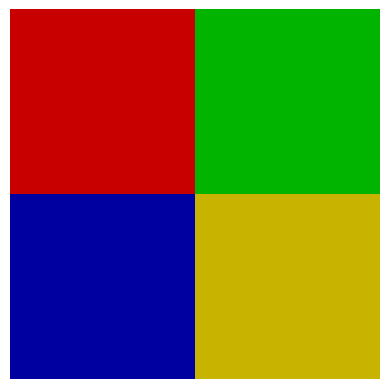

In [75]:
plt.imshow(picture, interpolation='nearest')
plt.axis('off');


У массива шаги `(6, 3, 1)`: следующая строка через шесть байт, следующий пиксель через три, следующий канал через один.


In [76]:
picture.strides


(6, 3, 1)

Чтобы оставить только красные значения, третью ось фиксируем индексом 0.


In [77]:
picture[:, :, 0]


array([[200,   0],
       [  0, 200]], dtype=uint8)

У `uint8` есть предел 255. Если сложить 250 и 10 в этом типе, получится переполнение.


In [78]:
byte = np.array([250], dtype=np.uint8)
byte + np.array([10], dtype=np.uint8)


array([4], dtype=uint8)

Для изменения яркости сначала расширяем тип, затем ограничиваем результат и только после этого возвращаем один байт. `np.clip` заменяет всё ниже 0 на 0, а всё выше 255 на 255. Это защищает от переполнения `uint8`.

In [79]:
np.clip(byte.astype(np.int16) + 10, 0, 255).astype(np.uint8)


array([255], dtype=uint8)

### **Фотография из файла**

До сих пор мы сами задавали четыре пикселя. Теперь возьмём фотографию из `Other/images/img.jpg`. Библиотека Pillow умеет открывать изображения; в коде она импортируется как `PIL`. Путь ниже записан относительно каталога этого ноутбука.

In [80]:
from pathlib import Path
from PIL import Image

photo_path = Path('../../Other/images/img.jpg')
photo_path

PosixPath('../../Other/images/img.jpg')

`Image.open` открывает JPEG. `convert('RGB')` оставляет три канала в одном порядке: красный, зелёный, синий. Затем `np.asarray` превращает пиксели в массив NumPy.

In [81]:
with Image.open(photo_path) as image:
    photo = np.asarray(image.convert('RGB'))

photo.shape, photo.dtype

((833, 1200, 3), dtype('uint8'))

Форма говорит о высоте, ширине и трёх каналах. Посмотрим сам снимок.


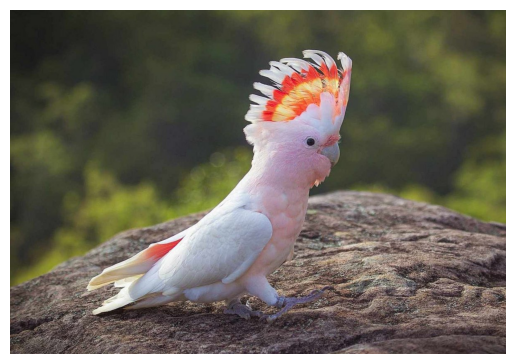

In [82]:
plt.imshow(photo)
plt.axis('off');


Первые 200 строк составляют верхнюю полосу. Каналы при этом остаются все три.


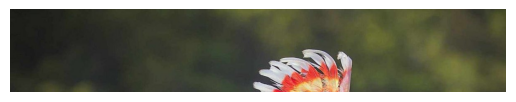

In [83]:
top = photo[:200]
plt.imshow(top)
plt.axis('off');


Срез `photo[::-1]` читает строки в обратном порядке. Он начинает с последней строки; шаг по первой оси становится **отрицательным** и ведёт к предыдущей строке в том же буфере.

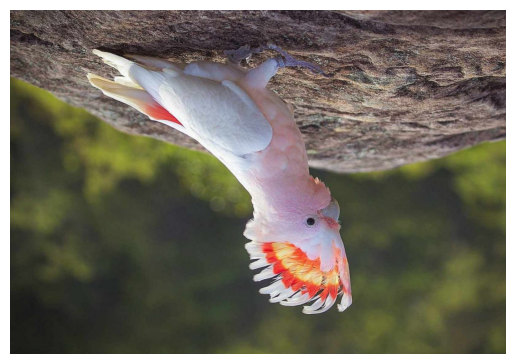

In [84]:
flipped = photo[::-1]
plt.imshow(flipped)
plt.axis('off');


Проверим знак шага. Его модуль равен числу байтов в одной строке фотографии; знак минус показывает направление чтения.

In [85]:
flipped.strides[0]

-3600

Теперь оставим один цвет видимым. Возьмём копию: запись в исходный массив изменила бы данные следующих примеров.


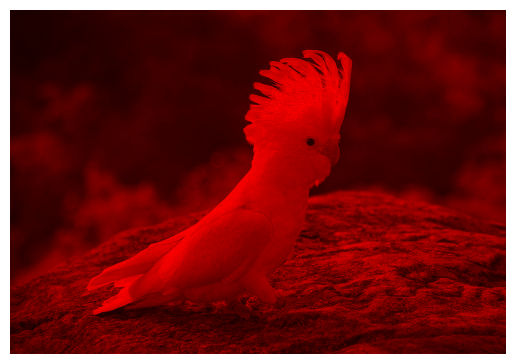

In [86]:
red_only = photo.copy()
red_only[:, :, 1:] = 0
plt.imshow(red_only)
plt.axis('off');


### **От цвета к яркости**

Начнём с более простого действия: умножим **все три канала** одного пикселя на `0.5`. Числа станут вдвое меньше, но их по-прежнему будет три. Мы изменили цвет пикселя, не превратили его в оттенок серого.

In [87]:
example_pixel = np.array([80, 160, 240], dtype=np.uint8)
example_pixel * 0.5

array([ 40.,  80., 120.])

С фотографией работает тот же приём: коэффициент применяется к каждому значению. Результат умножения вещественный; для показа RGB-изображения вернём его к `uint8`. При коэффициенте `0.5` значения остаются в пределах 0–255.

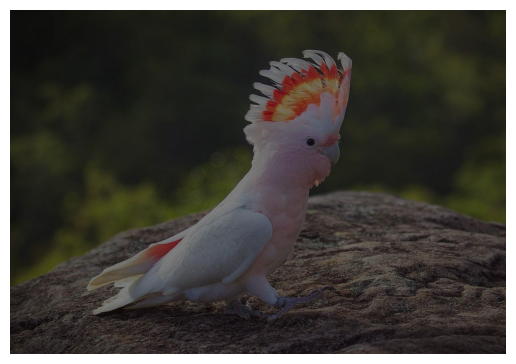

In [88]:
darker = (photo * 0.5).astype(np.uint8)
plt.imshow(darker)
plt.axis('off');

Теперь другая задача: нам нужно **одно число на пиксель**, чтобы изучать светлые и тёмные места как двумерную таблицу. Позже эту таблицу возьмём для SVD. Самый простой способ – среднее красного, зелёного и синего. Для нашего пикселя это `(80 + 160 + 240) / 3 = 160`.

In [89]:
example_pixel.mean()

np.float64(160.0)

Для всей фотографии берём среднее по оси 2 – оси трёх каналов. Получается форма `(высота, ширина)`: один результат вместо трёх чисел на каждом месте.

In [90]:
plain_gray = photo.mean(axis=2)
plain_gray.shape

(833, 1200)

Равные доли – простой первый способ, но чистые красный, зелёный и синий выглядят неодинаково светлыми. Поэтому для одного числа яркости используют разные веса каналов.

Числа `0.299`, `0.587`, `0.114` взяты из [стандарта BT.601](https://www.itu.int/dms_pubrec/itu-r/rec/bt/r-rec-bt.601-7-201103-i%21%21pdf-e.pdf). Наибольший вес у зелёного, наименьший – у синего. Это принятая формула яркостного сигнала для определённого представления RGB, а не универсальное правило для всех изображений. В сумме веса дают 1.

In [91]:
weights = np.array([0.299, 0.587, 0.114])
round(weights.sum(), 3)

np.float64(1.0)

Умножим каждый канал **одного** пикселя на свой вес. Здесь ещё три числа – вклады красного, зелёного и синего.

In [92]:
example_pixel * weights

array([23.92, 93.92, 27.36])

Сложим три вклада. Получится одно значение яркостного сигнала для этого пикселя.

In [93]:
(example_pixel * weights).sum()

np.float64(145.2)

На фотографии NumPy повторит тот же расчёт для каждого пикселя: ряд из трёх весов согласуется с последней осью массива. После умножения `sum(axis=2)` складывает три вклада и убирает ось каналов.

In [94]:
luma = (photo * weights).sum(axis=2)
luma.shape

(833, 1200)

Сравним два серых изображения на одной шкале от 0 до 255. Иначе `imshow` отдельно подстроил бы контраст каждого и сравнение стало бы нечестным. `plt.subplots(1, 2)` готовит две области рисунка.

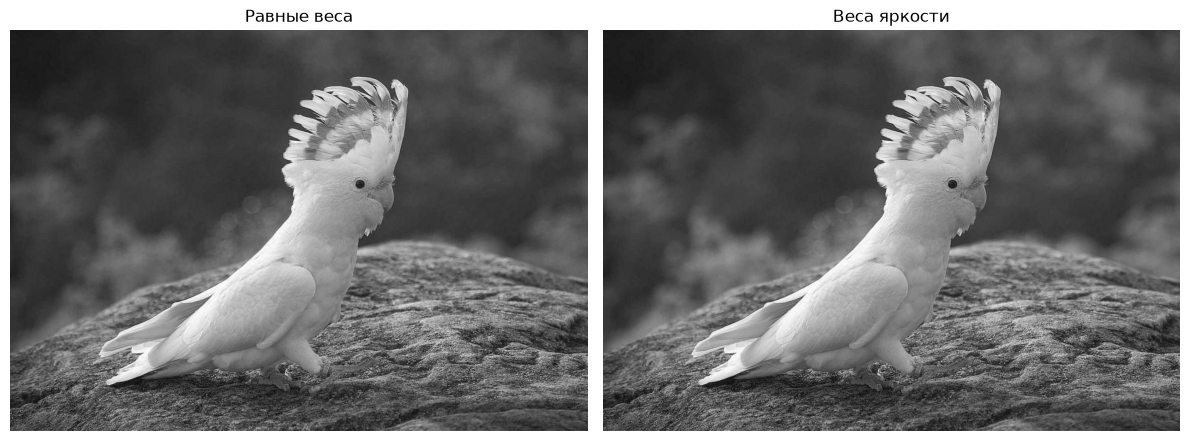

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, frame, title in zip(axes, [plain_gray, luma], ['Равные веса', 'Веса яркости']):
    ax.imshow(frame, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()


Снимки похожи – и это ожидаемо: большую часть сцены оба способа передают близко. Разница заметнее на участках с выраженным цветом. Здесь нам важно увидеть не эффектный фильтр, а два осмысленных способа получить **одно число на пиксель**.

## **Меньше данных**

Если нужен кадр меньшего разрешения, можно оставить каждую восьмую строку и каждый восьмой столбец. Так мы действительно уменьшаем число пикселей. Позже сравним этот приём с размытием, которое меняет значения соседних пикселей.

In [96]:
step = 8
sparse_view = photo[::step, ::step]
sparse_view.shape


(105, 150, 3)

Это срез: он по-прежнему может удерживать исходный большой буфер. Для самостоятельного небольшого массива сделаем копию.


In [97]:
sparse = sparse_view.copy()
photo.nbytes, sparse.nbytes, np.shares_memory(photo, sparse)


(2998800, 47250, False)

Проверим вид редкого кадра. Точек стало меньше, но сцена узнаваема.


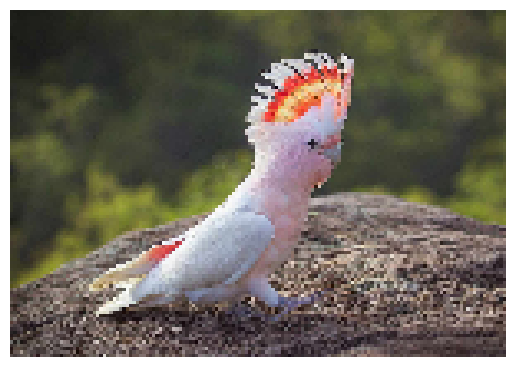

In [98]:
plt.imshow(sparse)
plt.axis('off');


### **`numpy.linalg`**

В математических домашних заданиях встретятся длина вектора, матричное произведение и разложения матриц. У NumPy для этого есть модуль `linalg`. Здесь нам нужен только короткий мостик к SVD: как меняются формы и чем `@` отличается от `*`.


In [99]:
vector = np.array([3., 4.])
np.linalg.norm(vector)


np.float64(5.0)

Норма этого вектора равна 5. Повернём его матрицей. У матрицы форма `(2, 2)`, у вектора `(2,)`, у результата снова `(2,)`.


In [100]:
rotation = np.array([[0., -1.], [1., 0.]])
turned = rotation @ vector
turned


array([-4.,  3.])

Такой поворот сохраняет длину. Знак `*` выполнил бы поэлементное умножение с согласованием форм, то есть другую операцию.


In [101]:
np.linalg.norm(turned)


np.float64(5.0)

### **SVD: маленький пример**

Прореживание удаляло пиксели. SVD оставляет сетку прежней, но приближает значения меньшим числом слагаемых. Для начала соберём матрицу ранга 1: каждая её строка пропорциональна первой. `np.outer` умножает каждое значение первого ряда на каждое значение второго.

In [102]:
left = np.array([1., 2.])
right = np.array([2., 1., 3.])
tiny = np.outer(left, right)
tiny


array([[2., 1., 3.],
       [4., 2., 6.]])

SVD (`np.linalg.svd`) разлагает матрицу на направления строк и столбцов и величины их вклада – сингулярные числа. Параметр `full_matrices=False` сразу оставляет компактные формы факторов. Для нашей матрицы посмотрим только на числа; `np.round` округлит их для удобства чтения.

In [103]:
u_tiny, s_tiny, vt_tiny = np.linalg.svd(tiny, full_matrices=False)
np.round(s_tiny, 8)


array([8.36660027, 0.        ])

Второе сингулярное число почти ноль. Одного слагаемого достаточно: столбец `U`, строка `Vt` и коэффициент `S` восстанавливают матрицу. `np.allclose` проверяет приблизительное равенство чисел с плавающей точкой: точного совпадения после вычислений ждать не стоит.

In [104]:
first_piece = s_tiny[0] * np.outer(u_tiny[:, 0], vt_tiny[0])
np.allclose(tiny, first_piece)


True

### **SVD фотографии**

Для учебного опыта возьмём каждую четвёртую точку серого снимка. Это ускоряет разложение. Результаты будем сравнивать **с этой же уменьшенной матрицей**, а не с исходным JPEG.


In [105]:
svd_image = luma[::4, ::4].copy()
U, S, Vt = np.linalg.svd(svd_image, full_matrices=False)
svd_image.shape, U.shape, S.shape, Vt.shape


((209, 300), (209, 209), (209,), (209, 300))

`full_matrices=False` оставляет компактные формы факторов. Первые сингулярные числа обычно крупнее следующих: ранние слагаемые описывают большую часть структуры снимка.


In [106]:
np.round(S[:5], 1)


array([24402.9,  5093.6,  3144.5,  3033.8,  2263.5])

Чтобы оставить ранг `r`, берём первые `r` столбцов `U`, чисел `S` и строк `Vt`. Broadcasting умножает каждый столбец на своё число; `@` собирает матрицу прежней формы.


In [107]:
def reconstruct(rank):
    return (U[:, :rank] * S[:rank]) @ Vt[:rank, :]

reconstruct(5).shape


(209, 300)

Сравним исходную уменьшенную яркость и три ранга. Все изображения показаны в одинаковой шкале от 0 до 255.


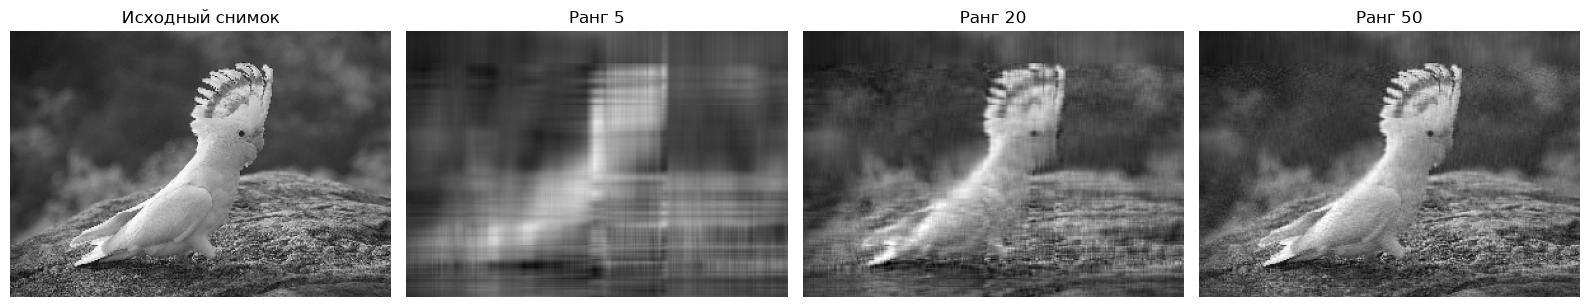

In [108]:
ranks = [5, 20, 50]
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
images = [svd_image] + [reconstruct(rank) for rank in ranks]
titles = ['Исходный снимок'] + [f'Ранг {rank}' for rank in ranks]
for ax, frame, title in zip(axes, images, titles):
    ax.imshow(np.clip(frame, 0, 255), cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()


Усечённые факторы ранга `r` содержат `r × (высота + ширина + 1)` чисел. Доля суммы квадратов сингулярных чисел показывает, какую часть энергии матрицы сохраняет приближение. Относительная ошибка по норме показывает, насколько изменились сами значения.


In [109]:
for rank in ranks:
    restored = reconstruct(rank)
    parameters = rank * (svd_image.shape[0] + svd_image.shape[1] + 1)
    energy = np.sum(S[:rank] ** 2) / np.sum(S ** 2)
    error = np.linalg.norm(svd_image - restored) / np.linalg.norm(svd_image)
    print(f'ранг {rank}: {parameters} чисел, энергия {energy:.1%}, ошибка {error:.1%}')


ранг 5: 2550 чисел, энергия 95.0%, ошибка 22.4%
ранг 20: 10200 чисел, энергия 97.6%, ошибка 15.5%
ранг 50: 25500 чисел, энергия 99.1%, ошибка 9.6%


Полное SVD во время вычисления хранит больше данных. Число параметров выше относится к **сохранённым усечённым факторам**, а не к размеру JPEG: файл уже сжат другим алгоритмом. Прореживание уменьшило разрешение; SVD сохранило сетку, но приблизило её значения.

---

## **Размытие**

Размытие усредняет соседние пиксели. Чтобы было видно, что оно меняет, сначала добавим фотографии шум – небольшие случайные поправки к цветам.

Начнём с одного пикселя и пока зададим поправки сами. Одни каналы станут больше, другие меньше.

In [110]:
pixel_for_noise = np.array([250, 10, 100], dtype=np.uint8)
change = np.array([12, -20, 5])
raw_pixel = pixel_for_noise.astype(np.int16) + change
raw_pixel

array([262, -10, 105])

Получились `262` и `-10`, хотя канал `uint8` допускает только целые от 0 до 255. Мы расширили тип **до сложения**, чтобы не получить переполнение. Теперь `np.clip` прижмёт всё ниже 0 к 0, а всё выше 255 к 255.

In [111]:
bounded_pixel = np.clip(raw_pixel, 0, 255)
bounded_pixel

array([255,   0, 105])

После ограничения три значения можно снова хранить как `uint8`.

In [112]:
bounded_pixel.astype(np.uint8)

array([255,   0, 105], dtype=uint8)

Теперь вместо придуманных поправок возьмём случайные. `rng.normal` создаст массив формы `photo.shape`: своё число для каждого канала каждого пикселя. `loc=0` задаёт центр, а `scale=12` – разброс, не предел.

In [113]:
rng = np.random.default_rng(42)
noise = rng.normal(loc=0, scale=12, size=photo.shape)
noise.shape

(833, 1200, 3)

Сложим шум и фотографию. Сначала переведём пиксели в вещественные числа: отрицательная поправка не должна переполнить `uint8`. Проверим крайние значения результата.

In [114]:
raw_noisy = photo.astype(np.float32) + noise
raw_noisy.min(), raw_noisy.max()

(np.float64(-35.583853512018635), np.float64(308.0513711957599))

Вернём значения в диапазон 0–255. Этот шаг меняет слишком маленькие и большие числа, но пока не меняет тип массива.

In [115]:
bounded_noisy = np.clip(raw_noisy, 0, 255)
bounded_noisy.min(), bounded_noisy.max()

(np.float64(0.0), np.float64(255.0))

Теперь преобразуем значения к `uint8` и посмотрим на снимок. Новый генератор с тем же зерном создаст тот же шум при повторном запуске этого опыта.

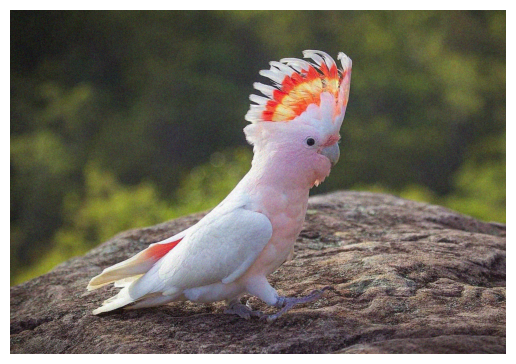

In [116]:
noisy = bounded_noisy.astype(np.uint8)
plt.imshow(noisy)
plt.axis('off');

Шум нарушил сходство соседних пикселей. Возьмём для каждого пикселя окно 3×3 и заменим его средним девяти чисел. На маленьком окне ниже легко проверить арифметику: в центре 90, вокруг нули.

In [117]:
patch = np.array([[0, 0, 0], [0, 90, 0], [0, 0, 0]], dtype=np.uint8)
patch.mean()


np.float64(10.0)

Среднее маленького окна равно 10. На фотографии такое окно нужно передвигать по всем пикселям. Первый срез ниже берёт верхние левые значения всех окон, второй – центральные.

In [118]:
patch[:-2, :-2], patch[1:-1, 1:-1]

(array([[0]], dtype=uint8), array([[90]], dtype=uint8))

В функции сложим три верхних среза, три средних и три нижних. Края кадра не попадут в результат: там нельзя собрать полное окно 3×3. Каналы цвета не сдвигаем – красный усредняется с красным.

In [119]:
def box_blur3(image):
    frame = image.astype(np.float32)  # Сумма байтов могла бы переполниться.
    top = frame[:-2, :-2] + frame[:-2, 1:-1] + frame[:-2, 2:]
    middle = frame[1:-1, :-2] + frame[1:-1, 1:-1] + frame[1:-1, 2:]
    bottom = frame[2:, :-2] + frame[2:, 1:-1] + frame[2:, 2:]

    return (top + middle + bottom) / 9

Проверим функцию на знакомом окне: должен получиться один пиксель со значением 10.

In [120]:
box_blur3(patch)

array([[10.]], dtype=float32)

Девять срезов обрабатывают все окна без Python-цикла по пикселям. Теперь применим функцию к шумной фотографии. Результат станет на два пикселя меньше по каждой пространственной оси.

In [121]:
blurred = box_blur3(noisy)
noisy.shape, blurred.shape

((833, 1200, 3), (831, 1198, 3))

Усреднение может сгладить шум, но смягчит и границы объектов. Поэтому смешаем шумный пиксель и среднее его соседей. При силе `0.3` берём 70% исходного значения и 30% среднего.

Для сложения размеры должны совпасть: обрежем один пиксель по краям шумного кадра.

In [122]:
noisy_crop = noisy[1:-1, 1:-1].astype(np.float32)
strength = 0.3

soft = (1 - strength) * noisy_crop + strength * blurred
soft.shape

(831, 1198, 3)

На полном кадре труднее увидеть, что произошло с соседними пикселями. Приблизим один и тот же участок и сравним три силы рядом. Усреднение сглаживает часть шума, но вместе с ним смягчает границы объектов.

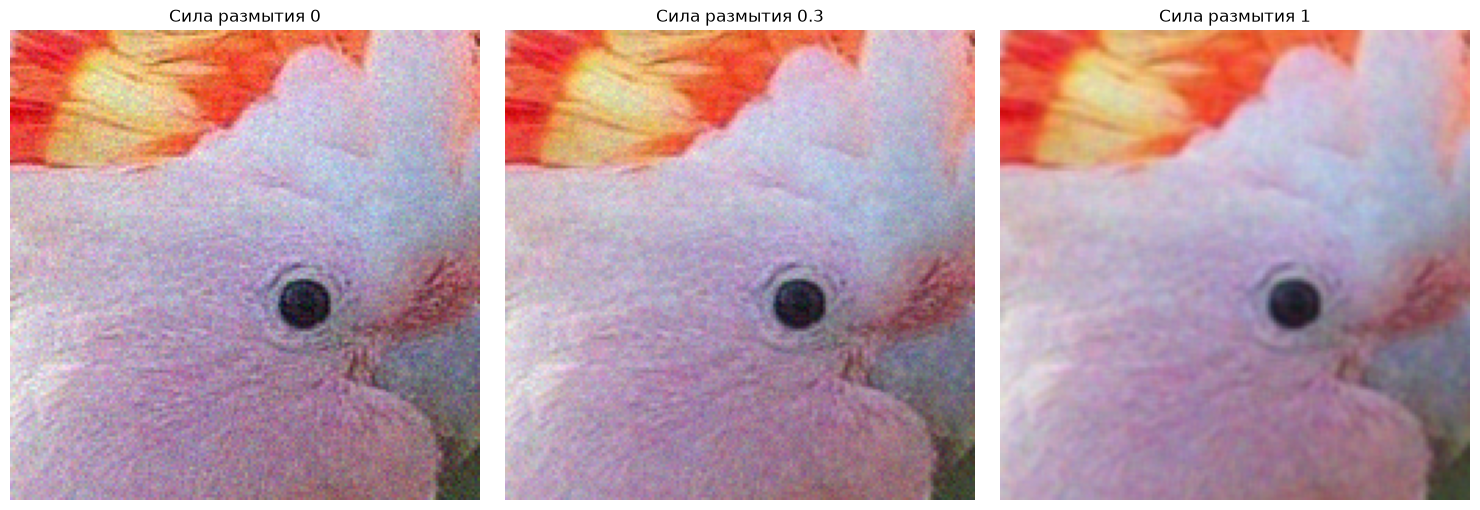

In [123]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, strength in zip(axes, [0.0, 0.3, 1.0]):
    mixed = (1 - strength) * noisy_crop + strength * blurred

    # Один и тот же участок крупным планом делает действие фильтра заметным.
    ax.imshow(np.clip(mixed[220:390, 620:790] / 255, 0, 1))
    ax.set_title(f'Сила размытия {strength:g}')
    ax.axis('off')

fig.tight_layout()

Прореживание удалило пиксели, SVD приблизило значения меньшим числом слагаемых, а размытие усреднило соседей. Эти три действия решают разные задачи, но каждое опирается на форму, тип, оси и правила операций с массивом.

---

## **Куда ведёт NumPy**

Форма массива, оси и операции над всеми значениями встречаются во многих библиотеках. У каждой своя задача:

- [pandas](https://pandas.pydata.org/docs/user_guide/dsintro.html) помогает работать с таблицами, метками строк и столбцов, пропусками. Многие его числовые столбцы используют массивы NumPy, хотя у pandas есть и другие типы хранения.
- [SciPy](https://scipy.org/) расширяет NumPy численными алгоритмами: оптимизацией, статистикой, интерполяцией, обработкой сигналов.
- [Matplotlib](https://matplotlib.org/stable/users/explain/quick_start.html) строит графики и показывает изображения; её `imshow` мы уже применяли.

Для анализа данных и машинного обучения понадобятся и другие инструменты:

- [scikit-learn](https://scikit-learn.org/stable/getting_started.html) обучает классические модели, подбирает параметры и оценивает качество. Матрица признаков обычно устроена как `(объекты, признаки)`.
- [xarray](https://docs.xarray.dev/en/latest/user-guide/data-structures.html) добавляет имена и координаты к многомерным массивам, например времени и широте.
- [Dask Array](https://docs.dask.org/en/latest/array.html) разбивает большие массивы на блоки и выполняет вычисления по частям.

В глубоком обучении массивные вычисления тоже остаются основой, но появляются дополнительные возможности:

- [PyTorch](https://docs.pytorch.org/tutorials/beginner/basics/tensor_tutorial.html) использует тензоры, вычисления на ускорителях и автоматическое дифференцирование для нейросетей.
- [JAX](https://docs.jax.dev/en/latest/quickstart.html) предлагает интерфейс массивов, похожий на NumPy, а также компиляцию, автоматическое дифференцирование и работу на ускорителях. У него есть отличия: например, массивы JAX нельзя изменять на месте.
- [CuPy](https://docs.cupy.dev/en/stable/overview.html) даёт NumPy-подобный интерфейс для массивов на GPU.

Знание устройства `ndarray` помогает читать код этих библиотек, хотя их массивы и правила исполнения не полностью совпадают.

---

## **Дополнительное чтение**

- [Типы данных NumPy](https://numpy.org/doc/stable/user/basics.types.html) – диапазоны чисел и преобразования.
- [Устройство `ndarray`](https://numpy.org/doc/stable/dev/internals.html) – буфер данных, форма и шаги.
- [Представления и копии](https://numpy.org/doc/stable/user/basics.copies.html) – когда массивы разделяют память.
- [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html) – правила согласования форм.
- [Универсальные функции](https://numpy.org/doc/stable/reference/ufuncs.html) – поэлементные операции NumPy.
- [`np.vectorize`](https://numpy.org/doc/stable/reference/generated/numpy.vectorize.html) – почему удобная обёртка не ускоряет Python-функцию.
- [`numpy.random`](https://numpy.org/doc/stable/reference/random/index.html) – функции, генератор и зерно.
- [SVD](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html) – разложение матрицы.
- [BT.601](https://www.itu.int/dms_pubrec/itu-r/rec/bt/r-rec-bt.601-7-201103-i%21%21pdf-e.pdf) – источник весов RGB для яркостного сигнала.
- [Array programming with NumPy](https://doi.org/10.1038/s41586-020-2649-2) – статья разработчиков о роли массивных вычислений.